# September MACD: Supertrend and pivots

The positive September ledger is confirmed. This companion compares actual recorded entry schedules and independently funded variants. Premium ST improves old active-window drawdown but fails the later book; pivot headroom selected in training fails both later checks. Read `FINDINGS.md` for the stopped-app distinction and valuation assumptions.

In [1]:
from pathlib import Path
import json,gzip,numpy as np,pandas as pd
import matplotlib.pyplot as plt
ROOT=Path('/Users/ramachandran/MACD-mini-ADV/research/september_supertrend_pivots_20261003')
results=pd.read_csv(ROOT/'results.csv')
with gzip.open(ROOT/'books.json.gz','rt') as f:books=json.load(f)
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

## Recorded baseline and funding
The old book has 3,070 fills and +Rs 27.25 L September realised increase. Its retained cash dipped to -Rs 9.61 L; the strict September replay rejects 31 unaffordable additions. The later app is a separate book.

In [2]:
json.loads((ROOT/'VALIDATION.json').read_text())

{'old_full': {'closing_cache_equity_parity': True,
  'funded_baseline_min_cash': 2315.2645000017947,
  'rejected_adds': 31,
  'rejected_entries': 0},
 'old_active': {'closing_cache_equity_parity': True,
  'funded_baseline_min_cash': 2315.2645000017947,
  'rejected_adds': 31,
  'rejected_entries': 0},
 'old_train': {'closing_cache_equity_parity': True,
  'funded_baseline_min_cash': 2315.2645000017947,
  'rejected_adds': 31,
  'rejected_entries': 0},
 'old_holdout': {'closing_cache_equity_parity': True,
  'funded_baseline_min_cash': 14.054600000104983,
  'rejected_adds': 0,
  'rejected_entries': 0},
 'current_sep': {'closing_cache_equity_parity': True,
  'funded_baseline_min_cash': 391.4554999991087,
  'rejected_adds': 0,
  'rejected_entries': 0},
 'old_source_book_unchanged': True,
 'old_source_book_sha256': 'c90d63c2c4d8a8479298dba7ba6dec58f4ad1ad30b34d33fe4e804a07918e58b',
 'recorded_baseline_exact_fill_reproduction': True,
 'recorded_baseline_september_realized_pnl': 2724699.20924453

## Funded comparisons
P&L includes causal archive marks. Old active: Sep 1–18; holdout: Sep 15–18; later book: Sep 29–30. Daily drawdown excludes intraday peaks.

In [3]:
rules=['baseline','premium_st','spot_st','pivot_room','both_st_room']
results[(results.extra_bps==0)&results.funded&results.cohort.isin(['old_active','old_holdout','current_sep'])&results.rule.isin(rules)][['cohort','rule','pnl','delta_pnl','max_drawdown','new_episodes','entry_day_p_holm']]

,cohort,rule,pnl,delta_pnl,max_drawdown,new_episodes,entry_day_p_holm
38,old_active,baseline,2.684656e+06,0.0000,1.096728e+06,621,NaN
40,old_active,premium_st,2.765144e+06,80487.9220,4.754313e+05,395,NaN
41,old_active,spot_st,2.324969e+06,-359686.9395,8.897078e+05,443,NaN
45,old_active,pivot_room,2.366921e+06,-317735.0715,8.507955e+05,462,NaN
47,old_active,both_st_room,2.171633e+06,-513022.9095,4.215175e+05,265,NaN
114,old_holdout,baseline,9.501318e+05,0.0000,1.260887e+06,269,NaN
116,old_holdout,premium_st,1.192040e+06,241907.7690,7.435123e+05,173,1.000000
117,old_holdout,spot_st,9.022119e+05,-47919.8600,1.225880e+06,215,1.000000
121,old_holdout,pivot_room,7.288486e+05,-221283.2510,1.050611e+06,203,1.000000
123,old_holdout,both_st_room,8.346580e+05,-115473.7645,7.519195e+05,126,1.000000


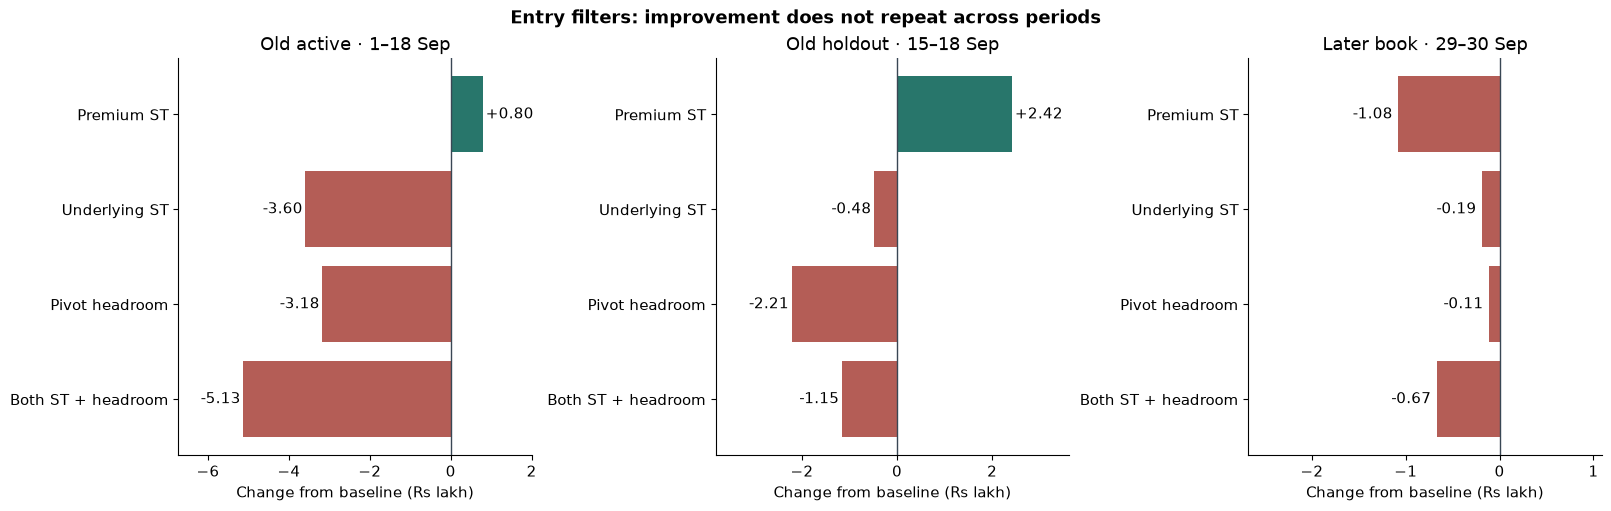

In [4]:
labels=['Premium ST','Underlying ST','Pivot headroom','Both ST + headroom']
fig,axes=plt.subplots(1,3,figsize=(16,5),layout='constrained')
for ax,cohort,title in zip(axes,['old_active','old_holdout','current_sep'],['Old active · 1–18 Sep','Old holdout · 15–18 Sep','Later book · 29–30 Sep']):
    block=results[(results.extra_bps==0)&results.funded&(results.cohort==cohort)].set_index('rule')
    values=block.loc[rules[1:],'delta_pnl'].to_numpy()/100000
    ax.barh(labels,values,color=['#28766b' if v>=0 else '#b45d56' for v in values])
    ax.axvline(0,color='#394754',lw=1);ax.invert_yaxis();ax.set_title(title);ax.set_xlabel('Change from baseline (Rs lakh)')
    for i,v in enumerate(values):ax.text(v+(0.06 if v>=0 else -.06),i,f'{v:+.2f}',ha='left' if v>=0 else 'right',va='center')
    ax.set_xlim(min(values)-1.6,max(values)+1.2)
fig.suptitle('Entry filters: improvement does not repeat across periods',fontweight='bold')
fig.savefig(ROOT/'incremental_comparison.png',dpi=150,bbox_inches='tight');plt.show()

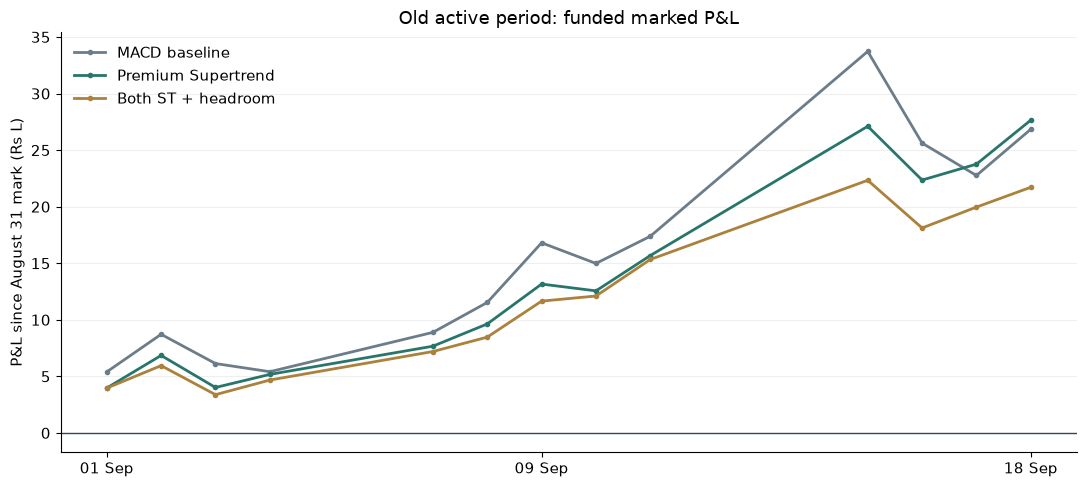

In [5]:
fig,ax=plt.subplots(figsize=(11,5))
for rule,label,color in [('baseline','MACD baseline','#6b7d8b'),('premium_st','Premium Supertrend','#28766b'),('both_st_room','Both ST + headroom','#ab813c')]:
    b=books['old_active|'+rule];date=pd.to_datetime([m['day'] for m in b['marks']]);pnl=np.array([m['equity']-b['start_mark']['equity'] for m in b['marks']])/100000
    ax.plot(date,pnl,label=label,color=color,lw=2,marker='o',ms=3)
ax.set_title('Old active period: funded marked P&L');ax.set_ylabel('P&L since August 31 mark (Rs L)');ax.axhline(0,color='#394754',lw=1);ax.legend(frameon=False);ax.grid(axis='y',alpha=.2)
ticks=date[[0,len(date)//2,-1]];ax.set_xticks(ticks);ax.set_xticklabels([d.strftime('%d %b') for d in ticks]);fig.tight_layout();fig.savefig(ROOT/'active_equity.png',dpi=150);plt.show()

## Full September scenario
The old app stopped recording fills on September 18. The month-end extension is a held-inventory/expiry-intrinsic scenario, not a continuously running strategy. Post-stop exit improvements must not be called indicator edge.

In [6]:
results[(results.cohort=='old_full')&results.funded&(results.extra_bps==0)][['rule','pnl','delta_pnl','max_drawdown']]

,rule,pnl,delta_pnl,max_drawdown
0,baseline,1.084015e+06,0.000000e+00,2.565760e+06
1,no_new_entries,1.185870e+06,1.018545e+05,1.779281e+05
2,premium_st,9.058210e+05,-1.781941e+05,1.874463e+06
3,spot_st,-9.572759e+04,-1.179743e+06,2.907908e+06
4,both_st,3.986547e+05,-6.853604e+05,2.246055e+06
5,premium_pivot,9.217864e+05,-1.622287e+05,2.970110e+06
6,spot_pivot,5.816857e+05,-5.023294e+05,2.403177e+06
7,pivot_room,1.172713e+06,8.869793e+04,2.113550e+06
8,both_st_pivot,1.718641e+05,-9.121510e+05,2.233750e+06
9,both_st_room,7.007252e+05,-3.832899e+05,1.564888e+06


## Training selection and validation
Headroom was selected only on Sep 1–11 and failed both later checks. No holdout threshold tuning.

In [7]:
json.loads((ROOT/'training_selection.json').read_text())

{'objective': 'Training-period funded marked P&L, including baseline and no-new-entry controls',
 'training_period': '1–11 September 2026',
 'selected_rule': 'pivot_room',
 'training_pnl': 1873885.2376000024,
 'training_delta': 135207.2395000048,
 'holdout': [{'cohort': 'old_holdout',
   'pnl': 728848.5560000017,
   'delta_pnl': -221283.25099999644,
   'entry_day_clusters': 4,
   'entry_day_p_holm': 1.0},
  {'cohort': 'current_sep',
   'pnl': -208369.7340000011,
   'delta_pnl': -11192.982499999924,
   'entry_day_clusters': 2,
   'entry_day_p_holm': 1.0}]}

In [8]:
pd.read_csv(ROOT/'entry_cost_sensitivity.csv').query("cohort in ['old_active','old_holdout','current_sep'] and rule in ['baseline','premium_st','pivot_room','both_st_room']")

,cohort,extra_bps,rule,pnl,delta_same_cost_baseline,max_daily_drawdown,new_episodes,rejected_entries,rejected_adds
30,old_active,0,baseline,2.684656e+06,0.000000,1.096728e+06,621,0,31
32,old_active,0,premium_st,2.765144e+06,80487.922000,4.754313e+05,395,0,9
37,old_active,0,pivot_room,2.366921e+06,-317735.071500,8.507955e+05,462,0,12
39,old_active,0,both_st_room,2.171633e+06,-513022.909500,4.215175e+05,265,0,9
40,old_active,20,baseline,2.463392e+06,0.000000,1.154753e+06,621,0,33
42,old_active,20,premium_st,2.601106e+06,137714.126262,4.967946e+05,395,0,9
47,old_active,20,pivot_room,2.182535e+06,-280856.951717,8.939296e+05,462,0,12
49,old_active,20,both_st_room,2.055127e+06,-408265.431745,4.379725e+05,265,0,9
50,old_active,50,baseline,2.080599e+06,0.000000,1.241790e+06,615,6,35
52,old_active,50,premium_st,2.336336e+06,255736.646405,5.288395e+05,395,0,9


In [9]:
alternate=pd.read_csv(ROOT/'source_sensitivity_current/results.csv')
comparison=results.merge(alternate,on=['cohort','rule','funded','extra_bps'],suffixes=('_oldsource','_newsource'))
comparison.query("funded and extra_bps==0 and rule in ['premium_st','pivot_room','both_st_room']") [['cohort','rule','delta_pnl_oldsource','delta_pnl_newsource']]

,cohort,rule,delta_pnl_oldsource,delta_pnl_newsource
2,old_full,premium_st,-178194.0780,-126917.7280
7,old_full,pivot_room,88697.9285,255261.5760
9,old_full,both_st_room,-383289.9095,-284835.6920
28,old_active,premium_st,80487.9220,131764.2720
33,old_active,pivot_room,-317735.0715,-296908.9240
35,old_active,both_st_room,-513022.9095,-556826.1920
54,old_train,premium_st,-170474.6795,-146624.3270
59,old_train,pivot_room,135207.2395,101354.2695
61,old_train,both_st_room,-205364.6900,-316004.5775
80,old_holdout,premium_st,241907.7690,300249.4415


## Interpretation
ST is a possible drawdown feature, not a validated mandatory gate. Pivot and ST combinations cut large winners and do not deliver stable profit improvements. Underlying-ST and pivot-loss exits benefit after the app stops but underperform during active trading. The filled-entry schedule excludes opportunities never funded by the apps. Source disagreements, some stale marks and only four plus two later entry sessions limit inference. No running strategy settings were changed.